In [1]:
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Locate dataset

possible_paths = [
    Path("data/raw"),
    Path("../data/raw")
]

DATA_DIR = next(
    (p for p in possible_paths
     if (p / "train.csv").exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Dataset not found")

# Load original datasets

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
test_label_df = pd.read_csv(DATA_DIR / "test_label.csv")

# Select 25 metric features

feature_cols = [
    col for col in train_df.columns
    if col.startswith("feature_")
]

# Handle verified boundary duplicate

same_timestamp = (
    train_df.iloc[-1]["timestamp_(min)"]
    == test_df.iloc[0]["timestamp_(min)"]
)

same_features = np.allclose(
    train_df.iloc[-1][feature_cols].to_numpy(dtype=float),
    test_df.iloc[0][feature_cols].to_numpy(dtype=float),
    equal_nan=True
)

if same_timestamp and same_features:

    test_eval_df = test_df.iloc[1:].copy().reset_index(drop=True)

    test_label_eval_df = (
        test_label_df.iloc[1:].copy().reset_index(drop=True)
    )

else:

    test_eval_df = test_df.copy().reset_index(drop=True)

    test_label_eval_df = (
        test_label_df.copy().reset_index(drop=True)
    )

# Verify alignment

assert np.array_equal(
    test_eval_df["timestamp_(min)"].to_numpy(),
    test_label_eval_df["timestamp_(min)"].to_numpy()
)

# Separate features and test labels

X_train_raw = train_df[feature_cols].copy()
X_test_raw = test_eval_df[feature_cols].copy()

y_test = test_label_eval_df["label"].astype(int)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)
print("Test labels:", y_test.shape)

print("\nData preparation successful!")

Training shape: (132481, 25)
Testing shape: (87840, 25)
Test labels: (87840,)

Data preparation successful!


In [3]:
# Create median imputer

imputer = SimpleImputer(strategy="median")

# Fit ONLY on training data

X_train = imputer.fit_transform(X_train_raw)

# Apply same imputer to test data

X_test = imputer.transform(X_test_raw)

# Convert back to DataFrames

X_train = pd.DataFrame(
    X_train,
    columns=feature_cols
)

X_test = pd.DataFrame(
    X_test,
    columns=feature_cols
)

print("Training missing values after imputation:",
      X_train.isnull().sum().sum())

print("Testing missing values after imputation:",
      X_test.isnull().sum().sum())

print("\nFinal training shape:", X_train.shape)
print("Final testing shape:", X_test.shape)

Training missing values after imputation: 0
Testing missing values after imputation: 0

Final training shape: (132481, 25)
Final testing shape: (87840, 25)


In [4]:
# Initialize Isolation Forest Model

isolation_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Train the model using training data

isolation_model.fit(X_train)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [5]:
# Generate predictions on unseen test data

raw_predictions = isolation_model.predict(X_test)

# Convert predictions:
# -1 = Anomaly
#  1 = Normal

y_pred = np.where(
    raw_predictions == -1,
    1,
    0
)

# Calculate anomaly scores
# Higher score = More anomalous

anomaly_scores = -isolation_model.decision_function(X_test)

print("Predictions generated successfully!")

print("\nPrediction Distribution:")

prediction_counts = pd.Series(y_pred).value_counts().reindex(
    [0, 1],
    fill_value=0
)

print("Normal predictions:", prediction_counts[0])
print("Anomaly predictions:", prediction_counts[1])

print(
    "\nPredicted anomaly percentage:",
    round((y_pred == 1).mean() * 100, 2),
    "%"
)

Predictions generated successfully!

Prediction Distribution:
Normal predictions: 77845
Anomaly predictions: 9995

Predicted anomaly percentage: 11.38 %


In [6]:
# Model Evaluation

# Convert values into NumPy arrays

y_true = np.asarray(y_test, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
scores = np.asarray(anomaly_scores, dtype=float)

# Verify data lengths

assert len(y_true) == len(y_pred) == len(scores)

# Calculate confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Calculate evaluation metrics

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_true, scores)

pr_auc = average_precision_score(y_true, scores)

# Display results

print("=" * 45)
print("ISOLATION FOREST - MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\nCONFUSION MATRIX VALUES")

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "Anomaly"],
        zero_division=0
    )
)

ISOLATION FOREST - MODEL EVALUATION
Accuracy  : 0.7375
Precision : 0.5664
Recall    : 0.2322
F1-Score  : 0.3294
ROC-AUC   : 0.7121
PR-AUC    : 0.4885

CONFUSION MATRIX VALUES
True Negatives : 59125
False Positives: 4334
False Negatives: 18720
True Positives : 5661

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.76      0.93      0.84     63459
     Anomaly       0.57      0.23      0.33     24381

    accuracy                           0.74     87840
   macro avg       0.66      0.58      0.58     87840
weighted avg       0.71      0.74      0.70     87840



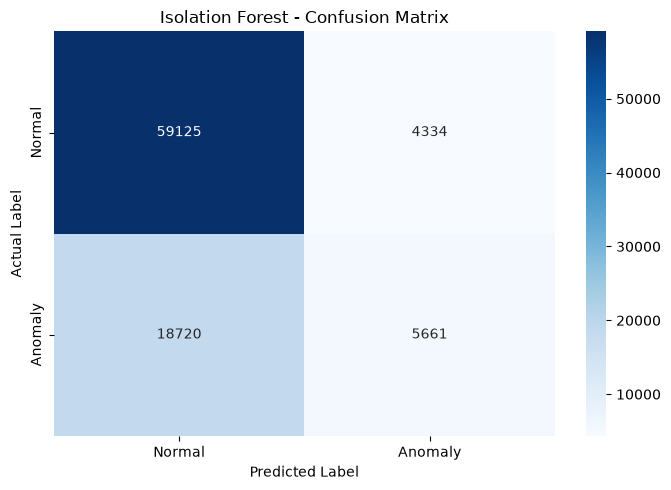

In [7]:
# Plot Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)

plt.title("Isolation Forest - Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

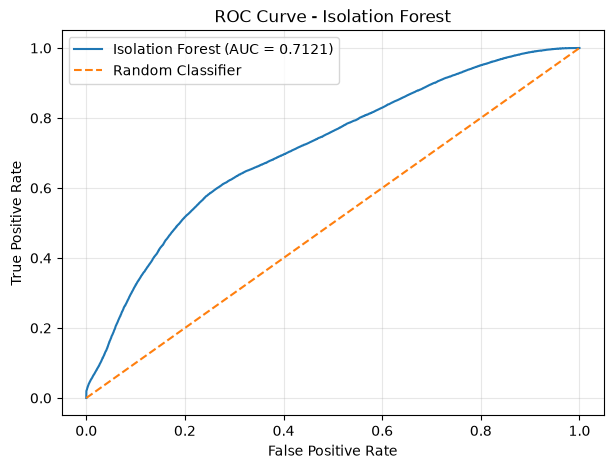

In [8]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

# ROC Curve
fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    scores
)

roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Isolation Forest (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Isolation Forest")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

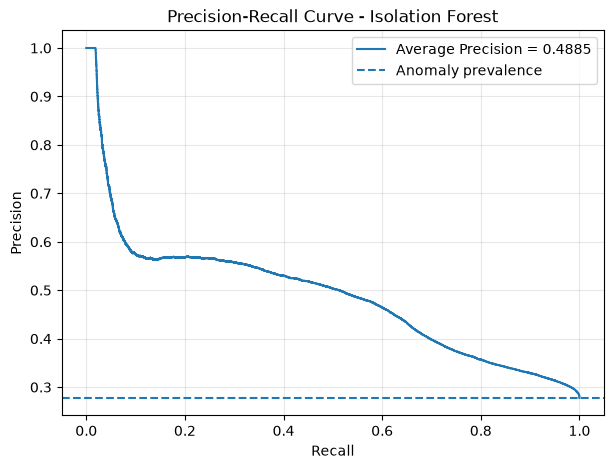

In [9]:
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_true, scores)
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {pr_auc:.4f}"
)

plt.axhline(
    y=y_true.mean(),
    linestyle="--",
    label="Anomaly prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - Isolation Forest")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

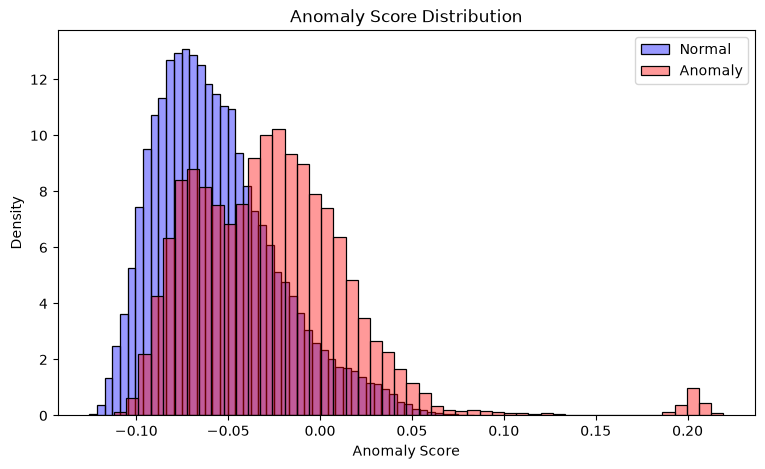

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    scores[y_true == 0],
    color="blue",
    label="Normal",
    bins=50,
    stat="density",
    alpha=0.4
)

sns.histplot(
    scores[y_true == 1],
    color="red",
    label="Anomaly",
    bins=50,
    stat="density",
    alpha=0.4
)

plt.xlabel("Anomaly Score")
plt.ylabel("Density")

plt.title("Anomaly Score Distribution")

plt.legend()
plt.show()

In [11]:
# Chronological validation and holdout split

split_index = int(len(y_true) * 0.30)

# Validation data - first half

y_val = y_true[:split_index]
scores_val = scores[:split_index]

# Holdout data - second half

y_holdout = y_true[split_index:]
scores_holdout = scores[split_index:]

print("VALIDATION DATA")
print("Records:", len(y_val))
print("Anomalies:", np.sum(y_val == 1))
print("Anomaly percentage:", round(y_val.mean() * 100, 2))

print("\nHOLDOUT DATA")
print("Records:", len(y_holdout))
print("Anomalies:", np.sum(y_holdout == 1))
print("Anomaly percentage:", round(y_holdout.mean() * 100, 2))

VALIDATION DATA
Records: 26352
Anomalies: 10208
Anomaly percentage: 38.74

HOLDOUT DATA
Records: 61488
Anomalies: 14173
Anomaly percentage: 23.05


In [12]:
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall on validation data

val_precision, val_recall, val_thresholds = (
    precision_recall_curve(y_val, scores_val)
)

# Calculate F2-score

f2_scores = (
    5 * val_precision[:-1] * val_recall[:-1]
    /
    (
        4 * val_precision[:-1]
        + val_recall[:-1]
        + 1e-10
    )
)

# Find best threshold

best_index = np.argmax(f2_scores)

best_threshold = val_thresholds[best_index]

best_f2 = f2_scores[best_index]

print("OPTIMAL THRESHOLD")
print("Best threshold:", best_threshold)

print("Validation Precision:",
      val_precision[best_index])

print("Validation Recall:",
      val_recall[best_index])

print("Validation F2-score:", best_f2)

OPTIMAL THRESHOLD
Best threshold: -0.09305481619885064
Validation Precision: 0.4446621832271857
Validation Recall: 0.9780564263322884
Validation F2-score: 0.7888125147853228


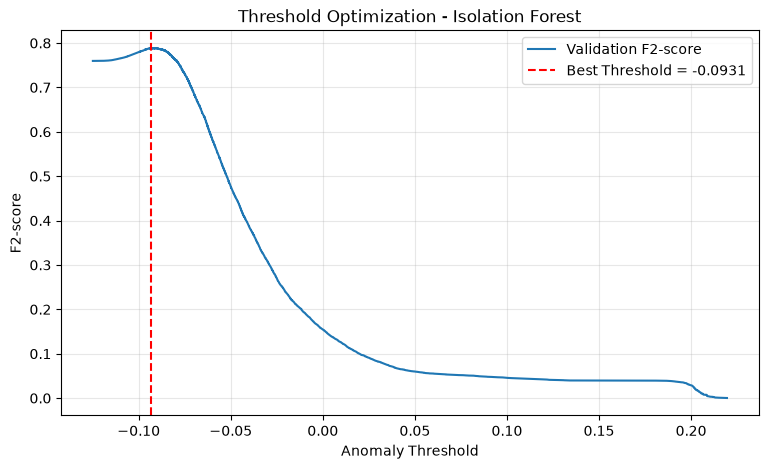

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    val_thresholds,
    f2_scores,
    label="Validation F2-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    color="red",
    label=f"Best Threshold = {best_threshold:.4f}"
)

plt.xlabel("Anomaly Threshold")
plt.ylabel("F2-score")

plt.title("Threshold Optimization - Isolation Forest")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
# Default threshold predictions

y_holdout_default = (
    scores_holdout > 0
).astype(int)

# Optimized threshold predictions

y_holdout_tuned = (
    scores_holdout > best_threshold
).astype(int)

# Compare performance

def evaluate_predictions(y_actual, y_prediction):

    return {
        "Accuracy": accuracy_score(
            y_actual, y_prediction
        ),

        "Precision": precision_score(
            y_actual, y_prediction, zero_division=0
        ),

        "Recall": recall_score(
            y_actual, y_prediction, zero_division=0
        ),

        "F1-score": f1_score(
            y_actual, y_prediction, zero_division=0
        ),

        "F2-score": (
            5 * precision_score(
                y_actual, y_prediction, zero_division=0
            ) * recall_score(
                y_actual, y_prediction, zero_division=0
            )
            /
            (
                4 * precision_score(
                    y_actual, y_prediction, zero_division=0
                )
                + recall_score(
                    y_actual, y_prediction, zero_division=0
                )
                + 1e-10
            )
        )
    }


comparison = pd.DataFrame(
    {
        "Default Threshold": evaluate_predictions(
            y_holdout, y_holdout_default
        ),

        "Tuned Threshold": evaluate_predictions(
            y_holdout, y_holdout_tuned
        )
    }
)

display(comparison.round(4))

,Default Threshold,Tuned Threshold
Accuracy,0.7770,0.2880
Precision,0.5279,0.2430
Recall,0.3066,0.9875
F1-score,0.3879,0.3900
F2-score,0.3346,0.6123


In [15]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

predictions = {
    "Default Threshold": y_holdout_default,
    "Tuned Threshold": y_holdout_tuned
}

results = {}

for name, pred in predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_holdout,
        pred,
        labels=[0, 1]
    ).ravel()

    results[name] = {
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Predicted Anomalies": int(pred.sum())
    }

display(pd.DataFrame(results).T)

,True Negatives,False Positives,False Negatives,True Positives,Predicted Anomalies
Default Threshold,43430,3885,9828,4345,8230
Tuned Threshold,3712,43603,177,13996,57599


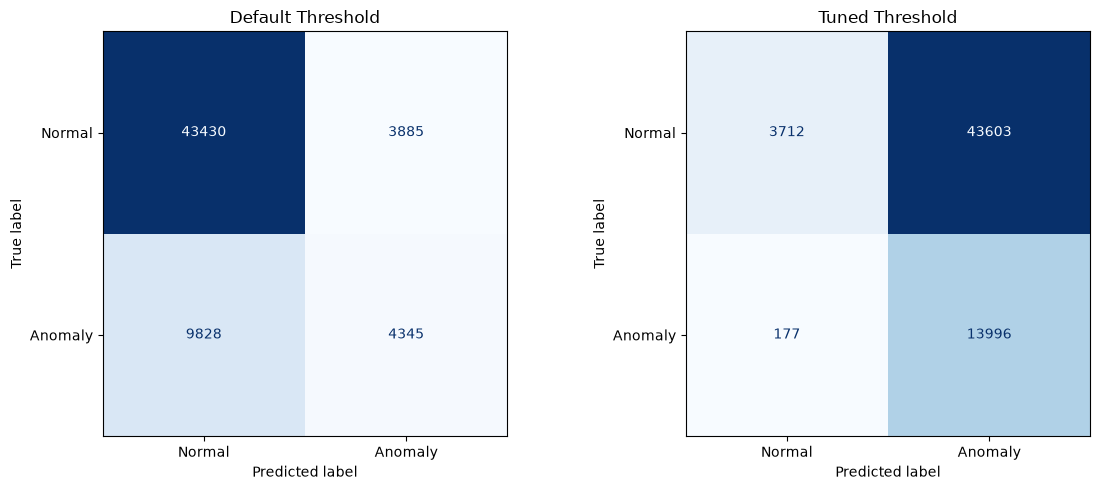

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(
    axes, predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_holdout,
        pred,
        display_labels=["Normal", "Anomaly"],
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [17]:
# Error Analysis - Tuned Isolation Forest

fp_indices = np.where(
    (y_holdout == 0) &
    (y_holdout_tuned == 1)
)[0]

fn_indices = np.where(
    (y_holdout == 1) &
    (y_holdout_tuned == 0)
)[0]

print("ERROR ANALYSIS")
print("=" * 40)

print("False Positives:", len(fp_indices))
print("False Negatives:", len(fn_indices))

print("\nFALSE POSITIVE SCORE ANALYSIS")

print(
    pd.Series(scores_holdout[fp_indices])
    .describe()
)

print("\nFALSE NEGATIVE SCORE ANALYSIS")

print(
    pd.Series(scores_holdout[fn_indices])
    .describe()
)

ERROR ANALYSIS
False Positives: 43603
False Negatives: 177

FALSE POSITIVE SCORE ANALYSIS
count    43603.000000
mean        -0.047070
std          0.031049
min         -0.093052
25%         -0.071141
50%         -0.052322
75%         -0.028977
max          0.083502
dtype: float64

FALSE NEGATIVE SCORE ANALYSIS
count    177.000000
mean      -0.097454
std        0.003352
min       -0.107960
25%       -0.099962
50%       -0.096609
75%       -0.094570
max       -0.093060
dtype: float64


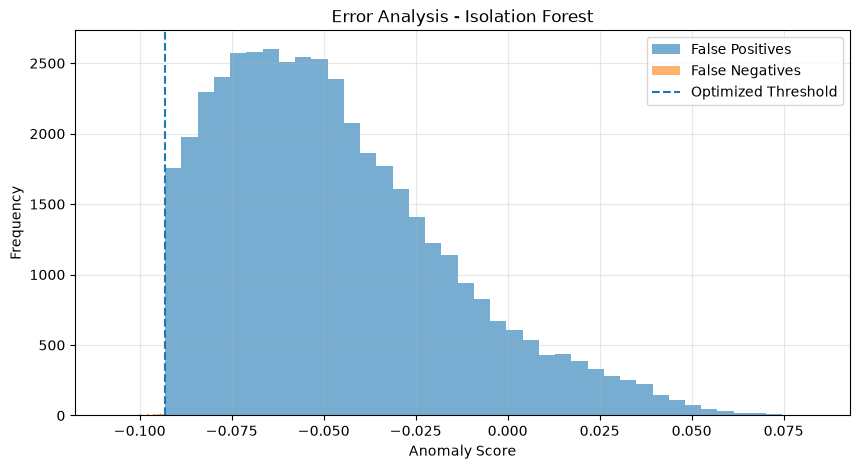

In [18]:
plt.figure(figsize=(10, 5))

plt.hist(
    scores_holdout[fp_indices],
    bins=40,
    alpha=0.6,
    label="False Positives"
)

plt.hist(
    scores_holdout[fn_indices],
    bins=40,
    alpha=0.6,
    label="False Negatives"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Optimized Threshold"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")

plt.title("Error Analysis - Isolation Forest")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [19]:
import time
from sklearn.base import clone

# ------------------------------------------
# 1. Create a fresh Isolation Forest model
# ------------------------------------------

runtime_model = clone(isolation_model)

# ------------------------------------------
# 2. Select the final holdout testing data
#    Use the same chronological split as Cell 10
# ------------------------------------------

runtime_split_index = split_index

X_holdout = X_test.iloc[runtime_split_index:].copy()

# Confirm that the holdout data matches the evaluation split
assert len(X_holdout) == len(y_holdout), (
    "Holdout feature and label counts do not match."
)

# ------------------------------------------
# 3. Measure Training Time
# ------------------------------------------

start_time = time.perf_counter()

runtime_model.fit(X_train)

training_time = time.perf_counter() - start_time

# ------------------------------------------
# 4. Measure Anomaly Scoring Time
# ------------------------------------------

start_time = time.perf_counter()

# Higher score indicates a more anomalous record
runtime_scores = -runtime_model.decision_function(X_holdout)

scoring_time = time.perf_counter() - start_time

# ------------------------------------------
# 5. Apply the Optimized Validation Threshold
# ------------------------------------------

start_time = time.perf_counter()

runtime_predictions = (
    runtime_scores > best_threshold
).astype(int)

threshold_time = time.perf_counter() - start_time

# ------------------------------------------
# 6. Calculate Runtime Performance
# ------------------------------------------

total_inference_time = scoring_time + threshold_time

records = len(X_holdout)

throughput = (
    records / total_inference_time
    if total_inference_time > 0
    else float("inf")
)

# ------------------------------------------
# 7. Display Results
# ------------------------------------------

print("=" * 55)
print("ISOLATION FOREST - RUNTIME ANALYSIS")
print("=" * 55)

print("\nDATASET INFORMATION")
print(f"Training Records    : {len(X_train)}")
print(f"Final Holdout Records: {records}")

print("\nRUNTIME RESULTS")
print(f"Training Time       : {training_time:.4f} seconds")
print(f"Scoring Time        : {scoring_time:.4f} seconds")
print(f"Threshold Time      : {threshold_time:.4f} seconds")
print(f"Total Inference Time: {total_inference_time:.4f} seconds")
print(f"Throughput          : {throughput:.2f} records/second")

print("\nIsolation Forest runtime analysis completed!")
print("=" * 55)


ISOLATION FOREST - RUNTIME ANALYSIS

DATASET INFORMATION
Training Records    : 132481
Final Holdout Records: 61488

RUNTIME RESULTS
Training Time       : 0.3611 seconds
Scoring Time        : 0.2126 seconds
Threshold Time      : 0.0001 seconds
Total Inference Time: 0.2127 seconds
Throughput          : 289031.99 records/second

Isolation Forest runtime analysis completed!
